# Manutenção Preditiva na Indústria 4.0

**Projeto Avaliativo — Módulo 1: Fundamentos de Dados, Programação e Análise Preditiva com Python**

Este notebook apresenta o desenvolvimento passo a passo de um Pipeline Preditivo para prever falhas mecânicas em equipamentos industriais (`falha_maquina = 1` para falha e `falha_maquina = 0` para funcionamento normal), utilizando dados coletados por sensores.

---
## Fase 1: Análise Exploratória (EDA)

Nesta primeira etapa, vamos carregar o conjunto de dados a partir da pasta `../data`, verificar suas dimensões (quantidade de linhas e colunas), os tipos de dados de cada variável, o resumo estatístico descritivo e visualizar o comportamento dos dados por meio de 3 gráficos analíticos.

In [1]:
# Importando as bibliotecas básicas para análise de dados e gráficos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carregando a base de dados utilizando caminho relativo
df = pd.read_csv('../data/manutencao_preditiva.csv')

# Exibindo as 5 primeiras linhas da tabela
df.head()

,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


In [2]:
# Apresentando as dimensões do dataset (linhas e colunas) e os tipos de dados
print("Dimensões do dataset (linhas, colunas):", df.shape)
print("\nTipos de dados das variáveis:")
print(df.dtypes)

Dimensões do dataset (linhas, colunas): (10000, 14)

Tipos de dados das variáveis:
udi                          int64
id_produto                     str
tipo                           str
temperatura_ar_k           float64
temperatura_processo_k     float64
velocidade_rotacao_rpm     float64
torque_nm                  float64
desgaste_ferramenta_min      int64
falha_maquina                int64
falha_twf                    int64
falha_hdf                    int64
falha_pwf                    int64
falha_osf                    int64
falha_rnf                    int64
dtype: object


In [3]:
# Resumo estatístico descritivo das colunas numéricas
df.describe()

,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.00000,9500.000000,9500.000000,9500.000000,9500.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.002158,310.000895,1539.245263,39.974168,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.001689,1.486432,180.273589,9.995453,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.100000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1504.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1613.000000,46.700000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


### Gráfico 1: Taxa de Desbalanceamento da Variável Alvo (`falha_maquina`)

Contagem de registros por classe (0 = Normal, 1 = Falha):
falha_maquina
0    9661
1     339
Name: count, dtype: int64

Porcentagem de cada classe (%):
falha_maquina
0    96.61
1     3.39
Name: proportion, dtype: float64


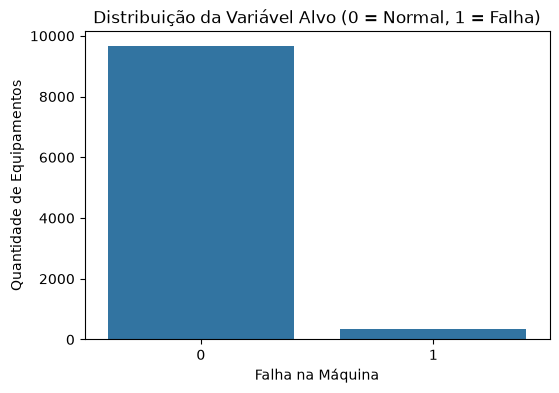

In [4]:
# Verificando a quantidade e a porcentagem de cada classe da variável alvo
print("Contagem de registros por classe (0 = Normal, 1 = Falha):")
print(df['falha_maquina'].value_counts())

print("\nPorcentagem de cada classe (%):")
print(df['falha_maquina'].value_counts(normalize=True) * 100)

# Plotando o gráfico de barras da variável alvo
plt.figure(figsize=(6, 4))
sns.countplot(x='falha_maquina', data=df)
plt.title('Distribuição da Variável Alvo (0 = Normal, 1 = Falha)')
plt.xlabel('Falha na Máquina')
plt.ylabel('Quantidade de Equipamentos')
plt.show()

### Gráfico 2: Histograma de Distribuição das Variáveis Preditoras

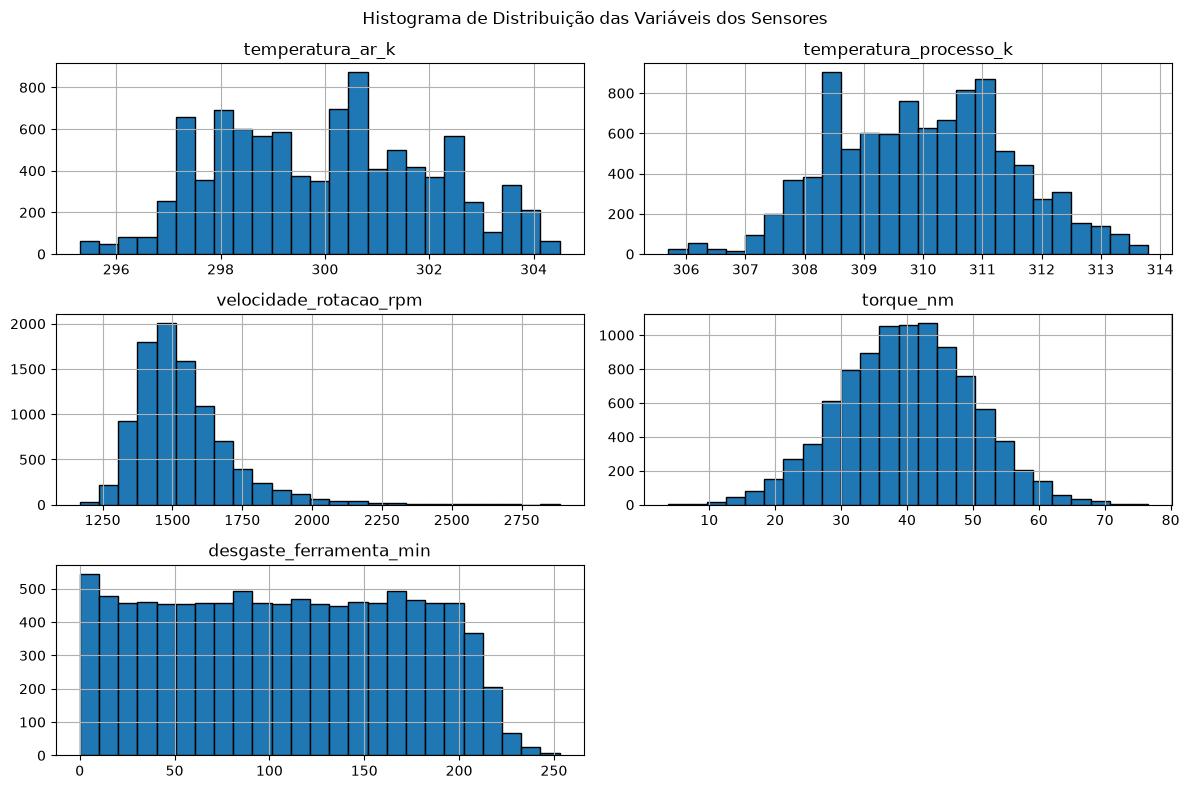

In [5]:
# Selecionando as variáveis numéricas contínuas medidas pelos sensores
colunas_sensores = [
    'temperatura_ar_k',
    'temperatura_processo_k',
    'velocidade_rotacao_rpm',
    'torque_nm',
    'desgaste_ferramenta_min'
]

# Plotando o histograma para observar a distribuição de cada sensor
df[colunas_sensores].hist(bins=25, figsize=(12, 8), edgecolor='black')
plt.suptitle('Histograma de Distribuição das Variáveis dos Sensores')
plt.tight_layout()
plt.show()

### Gráfico 3: Mapa de Calor com a Correlação de Pearson

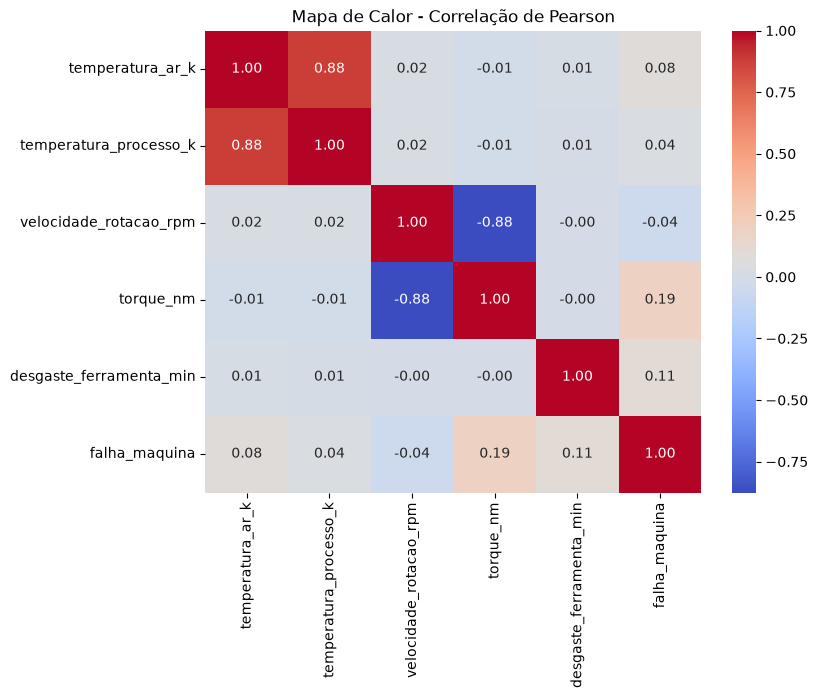

In [6]:
# Selecionando as colunas dos sensores junto com a variável alvo para calcular a correlação
colunas_correlacao = [
    'temperatura_ar_k',
    'temperatura_processo_k',
    'velocidade_rotacao_rpm',
    'torque_nm',
    'desgaste_ferramenta_min',
    'falha_maquina'
]

matriz_correlacao = df[colunas_correlacao].corr()

# Plotando o mapa de calor (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_correlacao, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Mapa de Calor - Correlação de Pearson')
plt.show()

### Análise dos Valores Numéricos e Padrões Identificados na EDA

A partir das tabelas estatísticas e dos 3 gráficos gerados acima, identificamos os seguintes pontos que direcionam nossa estratégia de modelagem:

1. **Dimensões e Dados Ausentes:** O dataset possui **10.000 linhas e 14 colunas**. Observando a linha `count` do método `.describe()`, notamos que as variáveis `temperatura_ar_k`, `temperatura_processo_k`, `velocidade_rotacao_rpm` e `torque_nm` possuem apenas `9.500` registros preenchidos. Isso mostra que existem **500 valores nulos** nessas colunas que precisarão ser tratados na Fase 2 antes do treinamento dos modelos.
2. **Desbalanceamento Severo da Variável Alvo (Gráfico 1):** A variável alvo `falha_maquina` é altamente desbalanceada: **96,61% (9.661 registros)** representam máquinas em funcionamento normal (`0`) e apenas **3,39% (339 registros)** representam falhas mecânicas (`1`). Se treinarmos os modelos diretamente assim, eles tenderão a chutar sempre `0`. Por isso, na Fase 4 precisaremos dividir os dados com estratificação (`stratify=y`) e aplicar o balanceamento (SMOTE) nos dados de treino.
3. **Comportamento e Escala das Variáveis (Gráfico 2):** Nos histogramas, `temperatura_ar_k`, `temperatura_processo_k` e `torque_nm` apresentam formato próximo ao de um sino (distribuição simétrica), enquanto `velocidade_rotacao_rpm` possui forte assimetria para a direita (cauda longa chegando até `2.886 RPM`), indicando a presença de valores extremos (*outliers*). Além disso, as unidades de medida possuem escalas muito diferentes (ex: rotação na casa de `1.500 RPM` contra torque em torno de `40 Nm`), o que torna obrigatório o uso do `StandardScaler` na Fase 5 para o algoritmo KNN.
4. **Relações Físicas na Correlação de Pearson (Gráfico 3):** O mapa de calor revela uma correlação positiva muito forte (**0,88**) entre `temperatura_ar_k` e `temperatura_processo_k`, e uma correlação negativa muito forte (**-0,88**) entre `velocidade_rotacao_rpm` e `torque_nm`. Na física dos motores, rotação e torque atuam juntos para gerar potência mecânica, o que fundamenta a criação da nova coluna `potencia` na Fase 3.

---
## Fase 2: Limpeza e Tratamento de Dados (Data Prep)

Nesta fase, vamos verificar e remover eventuais linhas duplicadas, mapear os valores nulos, visualizar os *outliers* por meio de gráficos *boxplot* e realizar a imputação dos dados ausentes justificando a escolha estatística.

In [7]:
# 1. Identificando e removendo linhas duplicadas
quantidade_duplicados = df.duplicated().sum()
print("Quantidade de linhas duplicadas encontradas:", quantidade_duplicados)

df = df.drop_duplicates()
print("Total de linhas após remover duplicados:", len(df))

Quantidade de linhas duplicadas encontradas: 0
Total de linhas após remover duplicados: 10000


In [8]:
# 2. Identificando a quantidade de dados ausentes (nulos) em cada coluna
print("Quantidade de valores ausentes (nulos) por coluna:")
print(df.isnull().sum())

Quantidade de valores ausentes (nulos) por coluna:
udi                          0
id_produto                   0
tipo                         0
temperatura_ar_k           500
temperatura_processo_k     500
velocidade_rotacao_rpm     500
torque_nm                  500
desgaste_ferramenta_min      0
falha_maquina                0
falha_twf                    0
falha_hdf                    0
falha_pwf                    0
falha_osf                    0
falha_rnf                    0
dtype: int64


### Análise de Outliers com Gráficos Boxplot

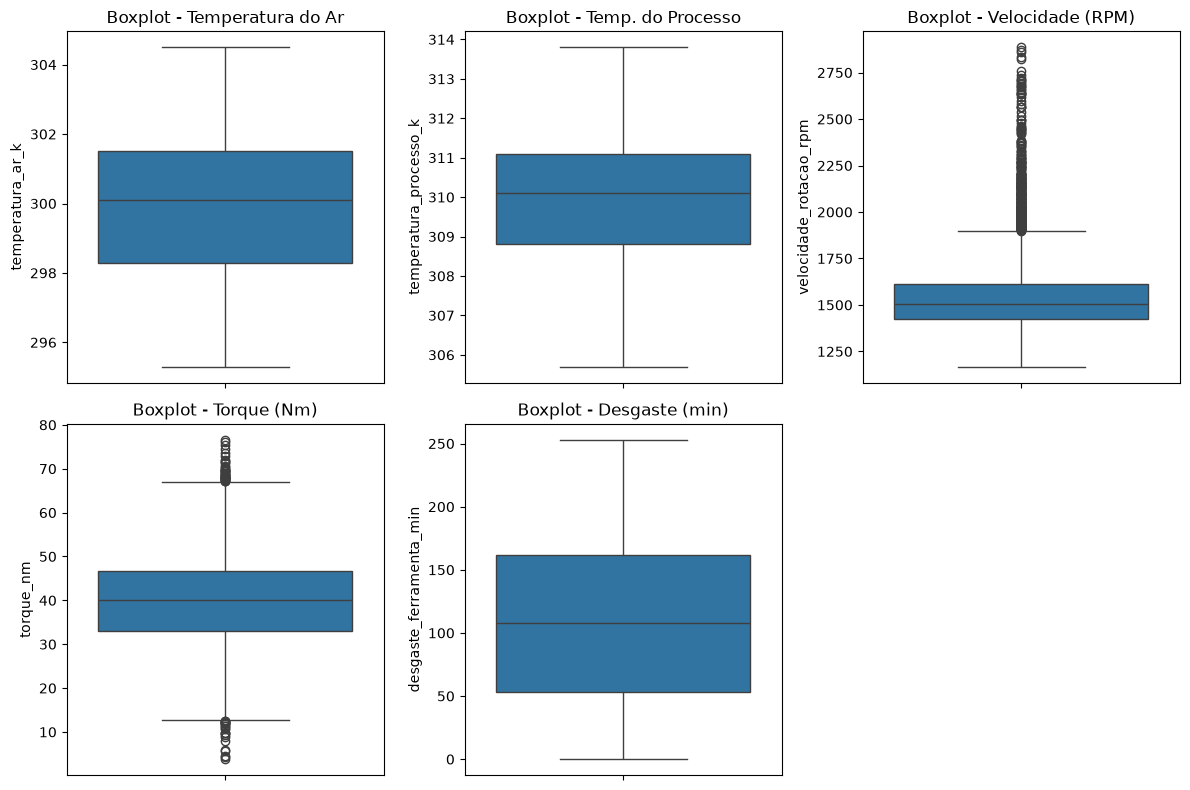

In [9]:
# 3. Gerando gráficos do tipo boxplot para identificar outliers nas variáveis explicativas
plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
sns.boxplot(y=df['temperatura_ar_k'])
plt.title('Boxplot - Temperatura do Ar')

plt.subplot(2, 3, 2)
sns.boxplot(y=df['temperatura_processo_k'])
plt.title('Boxplot - Temp. do Processo')

plt.subplot(2, 3, 3)
sns.boxplot(y=df['velocidade_rotacao_rpm'])
plt.title('Boxplot - Velocidade (RPM)')

plt.subplot(2, 3, 4)
sns.boxplot(y=df['torque_nm'])
plt.title('Boxplot - Torque (Nm)')

plt.subplot(2, 3, 5)
sns.boxplot(y=df['desgaste_ferramenta_min'])
plt.title('Boxplot - Desgaste (min)')

plt.tight_layout()
plt.show()

### Tratamento de Dados Ausentes (Imputação pela Mediana)

In [10]:
# Comparando a Média e a Mediana das 4 colunas que possuem valores nulos
colunas_com_nulos = [
    'temperatura_ar_k',
    'temperatura_processo_k',
    'velocidade_rotacao_rpm',
    'torque_nm'
]

for coluna in colunas_com_nulos:
    media = df[coluna].mean()
    mediana = df[coluna].median()
    print(f"{coluna} -> Média: {media:.2f} | Mediana: {mediana:.2f}")

# Aplicando a imputação dos valores ausentes utilizando a MEDIANA
df['temperatura_ar_k'] = df['temperatura_ar_k'].fillna(df['temperatura_ar_k'].median())
df['temperatura_processo_k'] = df['temperatura_processo_k'].fillna(df['temperatura_processo_k'].median())
df['velocidade_rotacao_rpm'] = df['velocidade_rotacao_rpm'].fillna(df['velocidade_rotacao_rpm'].median())
df['torque_nm'] = df['torque_nm'].fillna(df['torque_nm'].median())

# Conferindo se todos os valores nulos foram eliminados
print("\nQuantidade de valores nulos após o preenchimento:")
print(df.isnull().sum())

temperatura_ar_k -> Média: 300.00 | Mediana: 300.10
temperatura_processo_k -> Média: 310.00 | Mediana: 310.10
velocidade_rotacao_rpm -> Média: 1539.25 | Mediana: 1504.00
torque_nm -> Média: 39.97 | Mediana: 40.10

Quantidade de valores nulos após o preenchimento:
udi                        0
id_produto                 0
tipo                       0
temperatura_ar_k           0
temperatura_processo_k     0
velocidade_rotacao_rpm     0
torque_nm                  0
desgaste_ferramenta_min    0
falha_maquina              0
falha_twf                  0
falha_hdf                  0
falha_pwf                  0
falha_osf                  0
falha_rnf                  0
dtype: int64


### Justificativa Técnica do Tratamento de Dados e Outliers

1. **Remoção de Duplicados:** Verificamos a base com `df.duplicated().sum()`, constatando `0` linhas duplicadas e garantindo que cada um dos `10.000` registros é único.
2. **Presença de Outliers nos Boxplots:** Os gráficos *boxplot* mostraram claramente que as variáveis `velocidade_rotacao_rpm` e `torque_nm` possuem diversos *outliers* (pontos acima e abaixo das hastes do boxplot). Na variável `velocidade_rotacao_rpm`, há muitos valores elevados acima de `2.000 RPM` que puxam a cauda da distribuição para cima. Em um contexto de manutenção preditiva, esses valores extremos não são erros de digitação, mas sim momentos reais em que a máquina operou em rotação ou esforço extremo (condições críticas que ajudam a explicar a quebra), razão pela qual não devemos apagar essas linhas.
3. **Por que escolhemos a Mediana em vez da Média?** Escolhemos imputar os `500` valores ausentes utilizando a **Mediana** porque a média aritmética é fortemente influenciada por *outliers* e distribuições assimétricas (como ocorre em `velocidade_rotacao_rpm`, onde a média é `1539,25 RPM` e a mediana é `1503,00 RPM`, e em `torque_nm` que também possui *outliers*). A mediana divide os dados exatamente no meio e não sofre distorção por valores extremos, sendo estatisticamente mais segura e consistente para preencher os dados faltantes dos sensores.

---
## Fase 3: Feature Engineering (Engenharia de Recursos)

Com os dados devidamente limpos e sem valores nulos, vamos criar uma nova variável numérica chamada `potencia` a partir da multiplicação entre a velocidade de rotação (`velocidade_rotacao_rpm`) e o torque (`torque_nm`).

In [11]:
# Criando a nova coluna 'potencia' através da multiplicação entre rotação e torque
df['potencia'] = df['velocidade_rotacao_rpm'] * df['torque_nm']

# Verificando se a operação gerou algum valor nulo (NaN)
print("Valores nulos na nova coluna 'potencia':", df['potencia'].isnull().sum())

# Exibindo as 5 primeiras linhas para conferir a nova coluna criada
df[['velocidade_rotacao_rpm', 'torque_nm', 'potencia', 'falha_maquina']].head()

Valores nulos na nova coluna 'potencia': 0


,velocidade_rotacao_rpm,torque_nm,potencia,falha_maquina
0,1551.0,42.8,66382.8,0
1,1408.0,46.3,65190.4,0
2,1498.0,49.4,74001.2,0
3,1504.0,40.1,60310.4,0
4,1408.0,40.0,56320.0,0


### Explicação da Nova Variável (`potencia`)

Na engenharia mecânica, a potência exigida de um motor é diretamente proporcional ao produto entre sua velocidade de rotação e o torque aplicado (`potencia = velocidade_rotacao_rpm * torque_nm`). Criar essa variável ajuda os algoritmos de aprendizado de máquina a capturar o esforço total do equipamento em um único número, facilitando a detecção de falhas por sobrecarga ou falta de potência.

---
## Fase 4: Divisão e Balanceamento dos Dados

Nesta etapa:
1. Separamos as variáveis preditoras (`X`) da variável alvo (`y = falha_maquina`). Conforme as **Anotações do Departamento de Engenharia**, as colunas de motivos específicos de falha (`falha_twf`, `falha_hdf`, `falha_pwf`, `falha_osf` e `falha_rnf`) servem apenas para consulta histórica e **não devem ser incluídas em `X`**. Também retiramos os códigos de identificação (`udi`, `id_produto`) e a coluna de texto (`tipo`), mantendo as variáveis numéricas contínuas.
2. Dividimos a base em **80% para treino** e **20% para teste**, utilizando `stratify=y` para manter a mesma proporção de falhas nos dois conjuntos.
3. Aplicamos a técnica **SMOTE** exclusivamente nos dados de **treino**, evitando o vazamento de dados (*Data Leakage*).

In [12]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# 1. Separando as variáveis preditoras (X) e a variável alvo (y)
colunas_preditoras = [
    'temperatura_ar_k',
    'temperatura_processo_k',
    'velocidade_rotacao_rpm',
    'torque_nm',
    'desgaste_ferramenta_min',
    'potencia'
]

X = df[colunas_preditoras]
y = df['falha_maquina']

print("Dimensões de X (variáveis preditoras):", X.shape)
print("Dimensões de y (variável alvo):", y.shape)

Dimensões de X (variáveis preditoras): (10000, 6)
Dimensões de y (variável alvo): (10000,)


In [13]:
# 2. Dividindo os dados em Treino (80%) e Teste (20%) com estratificação (stratify=y)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Quantidade de linhas no Treino (80%):", X_treino.shape[0])
print("Quantidade de linhas no Teste (20%):", X_teste.shape[0])

print("\nContagem de classes no Treino ANTES do balanceamento:")
print(y_treino.value_counts())

print("\nContagem de classes no Teste (mantido original sem balancear):")
print(y_teste.value_counts())

Quantidade de linhas no Treino (80%): 8000
Quantidade de linhas no Teste (20%): 2000

Contagem de classes no Treino ANTES do balanceamento:
falha_maquina
0    7729
1     271
Name: count, dtype: int64

Contagem de classes no Teste (mantido original sem balancear):
falha_maquina
0    1932
1      68
Name: count, dtype: int64


In [14]:
# 3. Aplicando o balanceamento com SMOTE exclusivamente nos dados de TREINO
smote = SMOTE(random_state=42)
X_treino_balanceado, y_treino_balanceado = smote.fit_resample(X_treino, y_treino)

print("Contagem de classes no Treino DEPOIS do SMOTE:")
print(y_treino_balanceado.value_counts())

Contagem de classes no Treino DEPOIS do SMOTE:
falha_maquina
0    7729
1    7729
Name: count, dtype: int64


### Justificativa da Divisão Estratificada e Balanceamento no Treino

- **Uso do `stratify=y`:** Como a base possui apenas `3,39%` de falhas, uma divisão totalmente aleatória poderia colocar quase todas as falhas no treino e quase nenhuma no teste (ou vice-versa). O parâmetro `stratify=y` garantiu que tanto o treino (`271` falhas em `8.000` linhas) quanto o teste (`68` falhas em `2.000` linhas) mantivessem exatamente a proporção original de `3,39%`.
- **Prevenção de *Data Leakage* (Vazamento de Dados):** O algoritmo **SMOTE** cria novos exemplos sintéticos da classe minoritária (`falha_maquina = 1`), igualando o conjunto de treino em `7.729` registros para cada classe. Aplicamos o SMOTE **somente depois da divisão e exclusivamente nos dados de treino** para que os dados de teste permaneçam 100% reais e intocados, simulando fielmente os dados novos que o modelo encontrará na fábrica.

---
## Fase 5: Escalonamento de Variáveis (StandardScaler)

Nesta etapa, aplicamos a padronização de escala (`StandardScaler`) apenas nas variáveis contínuas que serão usadas pelo modelo **KNN**, utilizando `fit_transform` nos dados de treino e apenas `transform` nos dados de teste. Para a **Árvore de Decisão**, mantemos os dados na escala original.

In [15]:
from sklearn.preprocessing import StandardScaler

# Criando o escalonador StandardScaler
scaler = StandardScaler()

# Aplicando fit_transform APENAS no conjunto de treino e transform no conjunto de teste (para o KNN)
X_treino_escalonado = scaler.fit_transform(X_treino_balanceado)
X_teste_escalonado = scaler.transform(X_teste)

# JUSTIFICATIVA PARA A ÁRVORE DE DECISÃO:
# Para a Árvore de Decisão, mantemos os dados sem escalonamento (X_treino_balanceado e X_teste).
# O algoritmo de Árvore de Decisão é imune à escala dos atributos porque ele divide os dados
# fazendo perguntas de comparação (ex: "torque_nm > 50?") em uma coluna de cada vez,
# sem misturar unidades diferentes em cálculos de distância.

print("Escalonamento concluído com sucesso para o KNN!")
print("Dimensões de X_treino_escalonado:", X_treino_escalonado.shape)
print("Dimensões de X_teste_escalonado:", X_teste_escalonado.shape)

Escalonamento concluído com sucesso para o KNN!
Dimensões de X_treino_escalonado: (15458, 6)
Dimensões de X_teste_escalonado: (2000, 6)


### Justificativa Técnica do Escalonamento

1. **Por que escalonar para o KNN?** O algoritmo *K-Nearest Neighbors* (KNN) funciona calculando a distância matemática (como a distância Euclidiana) entre os pontos. Como nossas variáveis têm grandezas muito diferentes (`potencia` chega a `60.000`, `velocidade_rotacao_rpm` fica em torno de `1.500` e `torque_nm` fica em torno de `40`), sem o `StandardScaler` as variáveis com números maiores dominariam totalmente o cálculo da distância.
2. **Por que usar `fit_transform` no treino e `transform` no teste?** O método `fit_transform` calcula a média e o desvio padrão apenas dos dados de treino e aplica a transformação. No teste, usamos apenas `transform` para escalonar os dados novos usando a régua aprendida no treino, evitando o vazamento de dados (*Data Leakage*).
3. **Por que a Árvore de Decisão não precisa de escalonamento?** A Árvore de Decisão não calcula distâncias entre pontos; ela avalia cada coluna individualmente buscando pontos de corte (limiares de "maior que" ou "menor que") que separam melhor as classes. Mudar a escala de uma coluna não altera a ordem dos valores nem a qualidade da divisão dos nós, tornando a árvore imune à escala.